# Statistical Analysis of Swedish Municipal Voter Turnout

## Project
**Forecasting Voter Turnout Across Swedish Municipalities**

## Purpose

This notebook examines the statistical relationships between municipal voter
turnout and the socioeconomic and demographic predictors prepared in the
previous notebooks.

The analysis proceeds from simple to more complete regression models:

1. Simple regression using previous-election turnout.
2. Regression including election-year effects.
3. Multiple regression including socioeconomic and demographic predictors.
4. Municipality-clustered standard errors to account for repeated observations.
5. A joint significance test for the socioeconomic and demographic predictors.

The analysis is observational and municipality-level. Regression coefficients
are therefore interpreted as associations rather than causal effects.

In [1]:
# Import libraries

import pandas as pd
import matplotlib.pyplot as plt

# statsmodels is used for statistical regression
import statsmodels.formula.api as smf

## 1. Load and Inspect the Historical Dataset

The statistical analysis uses the cleaned historical dataset created in
`01_data_preparation.ipynb`.

The dataset contains 290 Swedish municipalities observed in the 2014, 2018
and 2022 Riksdag elections, giving 870 municipality-election observations.

In [2]:
# Load the cleaned historical modelling dataset.
# municipality_code is loaded as a string because it is an identifier,
# not a numerical measurement. This also preserves leading zeros.


master_df = pd.read_csv(
    "../data/processed/master_model_dataset_2014_2022.csv",
    dtype={"municipality_code": str}
)

# Basic dataset checks.

print("Shape:", master_df.shape)

print(
    "Unique municipalities:",
    master_df["municipality_code"].nunique()
)

print("\nRows per election:")
print(
    master_df["election_year"]
    .value_counts()
    .sort_index()
)

Shape: (870, 12)
Unique municipalities: 290

Rows per election:
election_year
2014    290
2018    290
2022    290
Name: count, dtype: int64


## 2. Simple Linear Regression

### Question

Does turnout in the previous election help explain turnout
in the current election?

### Model

Current Turnout = β₀ + β₁ × Previous Turnout + error

Where:

- β₀ = intercept
- β₁ = slope/coefficient for previous turnout
- error = variation in turnout not explained by previous turnout

In [3]:
# Fit a simple linear regression model.
#
# Left side of ~  = outcome/dependent variable
# Right side of ~ = predictor/independent variable
#
# Therefore:
# turnout_pct ~ previous_turnout_pct
#
# means:
# "Model current turnout using previous turnout."

model_previous = smf.ols(
    "turnout_pct ~ previous_turnout_pct",
    data=master_df
).fit()

# Display full statistical results
print(model_previous.summary())

                            OLS Regression Results                            
Dep. Variable:            turnout_pct   R-squared:                       0.563
Model:                            OLS   Adj. R-squared:                  0.562
Method:                 Least Squares   F-statistic:                     1118.
Date:                Sat, 12 Sep 2026   Prob (F-statistic):          3.76e-158
Time:                        13:06:49   Log-Likelihood:                -1798.3
No. Observations:                 870   AIC:                             3601.
Df Residuals:                     868   BIC:                             3610.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               19.9497 

### Interpretation

Previous-election turnout shows a strong positive association with current
municipal turnout.

The estimated coefficient for previous turnout is approximately **0.770**.
This means that, in this pooled model, a municipality with one percentage
point higher turnout in the previous election is associated with approximately
**0.77 percentage points higher turnout** in the current election.

The model has an \(R^2\) of approximately **0.563**, meaning that previous
turnout alone accounts for about 56.3% of the observed variation in current
municipal turnout in this pooled sample.

The coefficient has a 95% confidence interval of approximately
**0.724 to 0.815** and a p-value below 0.001, providing strong statistical
evidence of a positive association under the ordinary OLS model.

However, this simple model does not yet account for differences between
elections or repeated observations of the same municipalities. These issues
are addressed in the following models.

In [4]:
# Generate fitted (predicted) turnout values from the simple regression.

master_df["predicted_turnout_simple"] = (
    model_previous.fittedvalues
)


# Calculate residuals.
#
# residual = actual turnout - predicted turnout
#
# Positive residual  -> model underpredicted turnout
# Negative residual  -> model overpredicted turnout

master_df["residual_simple"] = (
    model_previous.resid
)

## 3. Residual Diagnostics for the Simple Model

Residuals are examined to understand where the previous-turnout-only model
makes systematic errors.

A residual is defined as:

\[
Residual = Actual\ Turnout - Predicted\ Turnout
\]

Positive residuals indicate underprediction, while negative residuals indicate
overprediction.

In [5]:
# Summarize residuals separately for each election.
# A systematic positive or negative mean residual suggests that
# the simple model is missing an election-wide shift.

residual_summary = (
    master_df
    .groupby("election_year")["residual_simple"]
    .agg(
        mean_residual="mean",
        median_residual="median",
        std_residual="std"
    )
    .round(3)
)

residual_summary

,mean_residual,median_residual,std_residual
election_year,,,
2014,1.057,1.196,0.985
2018,1.146,1.254,0.837
2022,-2.203,-2.035,1.423


In [6]:
master_df[
    [
        "municipality_name",
        "election_year",
        "previous_turnout_pct",
        "turnout_pct",
        "predicted_turnout_simple",
        "residual_simple"
    ]
].head(10)

,municipality_name,election_year,previous_turnout_pct,turnout_pct,predicted_turnout_simple,residual_simple
0,Upplands Väsby,2014,83.2,84.1,83.982945,0.117055
1,Upplands Väsby,2018,84.1,84.7,84.675612,0.024388
2,Upplands Väsby,2022,84.7,79.5,85.137390,-5.637390
3,Vallentuna,2014,87.6,89.3,87.369318,1.930682
4,Vallentuna,2018,89.3,90.0,88.677689,1.322311
5,Vallentuna,2022,90.0,87.4,89.216430,-1.816430
6,Österåker,2014,87.3,88.2,87.138428,1.061572
7,Österåker,2018,88.2,89.3,87.831096,1.468904
8,Österåker,2022,89.3,87.3,88.677689,-1.377689
9,Värmdö,2014,87.7,89.3,87.446281,1.853719


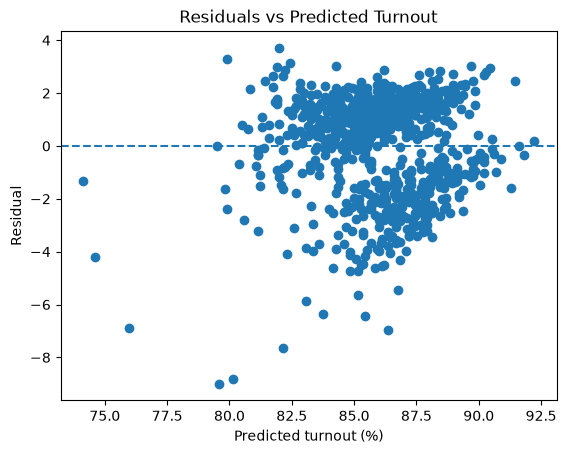

In [7]:
# Plot residuals against predicted turnout for the simple model.
#
# This helps check whether prediction errors are randomly scattered
# around zero or whether there is a systematic pattern.


plt.scatter(
    master_df["predicted_turnout_simple"],
    master_df["residual_simple"]
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted turnout (%)")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted Turnout")
plt.show()

### Initial residual pattern

The residuals are not distributed completely randomly around zero, suggesting
that the previous-turnout-only model may be missing systematic variation.

To investigate whether this pattern differs across elections, the residuals
are examined separately by election year.

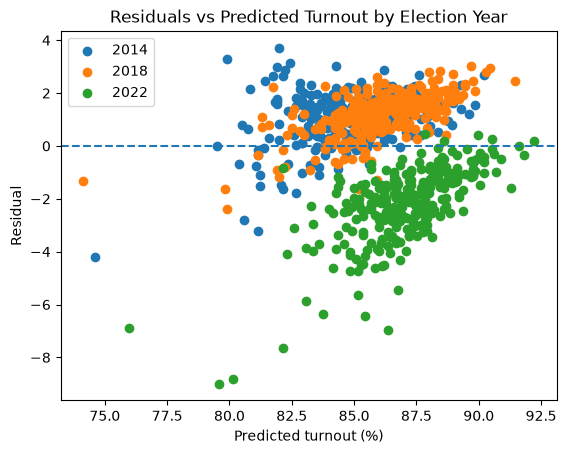

In [8]:
# Plot residuals separately by election year.
#
# This helps identify whether the simple model systematically
# overpredicts or underpredicts turnout in particular elections.




for year in sorted(master_df["election_year"].unique()):

    subset = master_df[
        master_df["election_year"] == year
    ]

    plt.scatter(
        subset["predicted_turnout_simple"],
        subset["residual_simple"],
        label=str(year)
    )

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted turnout (%)")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted Turnout by Election Year")
plt.legend()
plt.show()

### Interpretation by election year

The year-specific residual plot reveals a clearer pattern than the pooled plot.

In particular, 2022 observations tend to have more negative residuals,
indicating that the simple model systematically overpredicts turnout in that
election.

This suggests that previous-election turnout alone does not capture
election-wide changes in turnout, motivating the inclusion of election-year
effects in the next regression model.

In [9]:
# Identify the municipalities where the simple model
# overpredicted turnout the most.
#
# Because:
# residual = actual turnout - predicted turnout
#
# the most negative residuals correspond to the largest overpredictions.

largest_overpredictions = (
    master_df[
        [
            "municipality_name",
            "election_year",
            "turnout_pct",
            "predicted_turnout_simple",
            "residual_simple"
        ]
    ]
    .sort_values(
        "residual_simple"
    )
    .head()
)

largest_overpredictions.round(2)

,municipality_name,election_year,turnout_pct,predicted_turnout_simple,residual_simple
53,Södertälje,2022,70.6,79.60,-9.00
23,Botkyrka,2022,71.3,80.13,-8.83
293,Burlöv,2022,74.5,82.14,-7.64
14,Järfälla,2022,79.4,86.37,-6.97
866,Haparanda,2022,69.1,75.98,-6.88


### Largest overpredictions

The most negative residuals identify cases where the simple
previous-turnout model predicted substantially higher turnout than was
actually observed.

These cases help identify municipalities and elections where historical
turnout alone performed poorly.

In [10]:
# Identify the municipalities where the simple model
# underpredicted turnout the most.
#
# Positive residuals mean:
# actual turnout > predicted turnout.

largest_underpredictions = (
    master_df[
        [
            "municipality_name",
            "election_year",
            "turnout_pct",
            "predicted_turnout_simple",
            "residual_simple"
        ]
    ]
    .sort_values(
        "residual_simple",
        ascending=False
    )
    .head()
)

largest_underpredictions.round(2)

,municipality_name,election_year,turnout_pct,predicted_turnout_simple,residual_simple
807,Dorotea,2014,85.7,81.98,3.72
573,Årjäng,2014,83.2,79.90,3.30
681,Älvdalen,2014,85.6,82.44,3.16
67,Vaxholm,2018,92.7,89.68,3.02
696,Säter,2014,87.3,84.29,3.01


### Largest underpredictions

The most positive residuals identify cases where actual turnout was
substantially higher than predicted by the previous-turnout-only model.

Together with the largest overpredictions, these observations illustrate
where the simple historical-turnout relationship does not fully explain
municipal turnout.

## 4. Regression with Election-Year Effects

The residual analysis suggests that the relationship between previous turnout
and current turnout is affected by systematic differences between elections.

To account for these election-wide shifts, election year is added as a
categorical variable.

The model is:

\[
Turnout_t =
\beta_0 +
\beta_1 PreviousTurnout_t +
ElectionYear +
\epsilon
\]

`C(election_year)` instructs `statsmodels` to treat election year as a
categorical variable rather than as a continuous numerical predictor.

The 2014 election is used as the reference category.

In [11]:
# Fit an OLS regression using:
# 1. previous-election turnout
# 2. categorical election-year effects
#
# C(election_year) creates indicator variables for 2018 and 2022.
# The 2014 election becomes the reference category.

model_year = smf.ols(
    "turnout_pct ~ previous_turnout_pct + C(election_year)",
    data=master_df
).fit()

print(model_year.summary())

                            OLS Regression Results                            
Dep. Variable:            turnout_pct   R-squared:                       0.896
Model:                            OLS   Adj. R-squared:                  0.896
Method:                 Least Squares   F-statistic:                     2487.
Date:                Sat, 12 Sep 2026   Prob (F-statistic):               0.00
Time:                        13:06:50   Log-Likelihood:                -1173.7
No. Observations:                 870   AIC:                             2355.
Df Residuals:                     866   BIC:                             2375.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept               

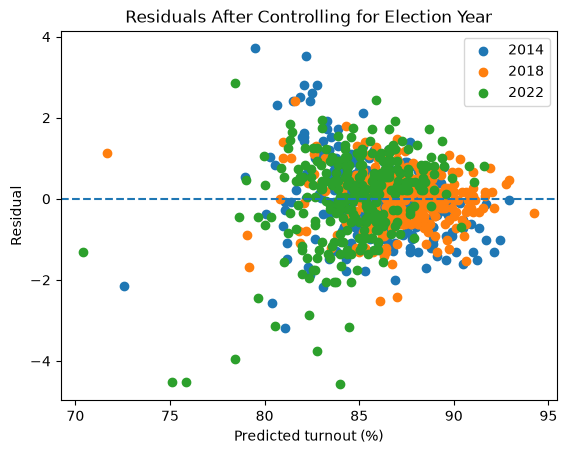

In [12]:
# Generate predicted turnout values from the model
# that includes both previous turnout and election-year effects.
master_df["predicted_turnout_year"] = model_year.fittedvalues

# Calculate residuals:
# residual = actual turnout - predicted turnout
master_df["residual_year"] = model_year.resid


# Plot residuals separately for each election year
for year in sorted(master_df["election_year"].unique()):

    # Select observations belonging to one election year
    subset = master_df[
        master_df["election_year"] == year
    ]

    # Plot predicted turnout against residuals
    plt.scatter(
        subset["predicted_turnout_year"],
        subset["residual_year"],
        label=str(year)
    )


# Horizontal zero line:
# points above = model underpredicted
# points below = model overpredicted
plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted turnout (%)")
plt.ylabel("Residual")
plt.title("Residuals After Controlling for Election Year")

# Show which points belong to each election
plt.legend()

plt.show()

### Interpretation

Adding election-year effects substantially improves model fit. The \(R^2\)
increases from approximately **0.563** in the previous-turnout-only model to
approximately **0.896**.

The coefficient for previous turnout is approximately **1.004**, indicating
that, after accounting for election year, one percentage point higher previous
turnout is associated with approximately one percentage point higher current
turnout.

Relative to the 2014 reference election, the estimated 2022 effect is strongly
negative, indicating an election-wide decline in turnout that could not be
captured by previous municipal turnout alone.

The residual plot also shows that the strong election-specific separation
observed in the simple model is substantially reduced after including
election-year effects.

## 5. Full Multiple Linear Regression

The previous model showed that previous turnout and election-year effects
explain a large proportion of variation in municipal turnout.

The next model adds the five socioeconomic and demographic predictors:

- Median disposable household income
- Registered unemployment
- Higher education
- Average age
- Log population density

The purpose is to examine whether these variables provide additional
information about turnout after controlling for previous turnout and
election-specific differences.

Because all predictors are included simultaneously, each coefficient represents
an adjusted association while holding the other variables in the model constant.

In [13]:
# Define the full regression formula.
#
# Outcome:
# turnout_pct = current municipal voter turnout
#
# Predictors:
# - previous-election turnout
# - socioeconomic and demographic characteristics
# - categorical election-year effects

full_formula = """
turnout_pct ~
previous_turnout_pct +
median_income_ksek +
registered_unemployed_pct +
higher_education_pct +
average_age +
log_population_density +
C(election_year)
"""


# Fit the full ordinary least-squares regression model.

model_full = smf.ols(
    full_formula,
    data=master_df
).fit()


# Display the regression results.

print(model_full.summary())

                            OLS Regression Results                            
Dep. Variable:            turnout_pct   R-squared:                       0.918
Model:                            OLS   Adj. R-squared:                  0.917
Method:                 Least Squares   F-statistic:                     1201.
Date:                Sat, 12 Sep 2026   Prob (F-statistic):               0.00
Time:                        13:06:51   Log-Likelihood:                -1071.7
No. Observations:                 870   AIC:                             2161.
Df Residuals:                     861   BIC:                             2204.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
Intercept             

### Interpretation of the Full Multiple Regression

The full model explains approximately **91.8%** of the observed variation in
municipal voter turnout (`R² = 0.918`, adjusted `R² = 0.917`), compared with
approximately 89.6% for the model containing only previous turnout and
election-year effects.

Previous turnout remains strongly associated with current turnout. Holding the
other variables and election year constant, one percentage point higher
previous turnout is associated with approximately **0.98 percentage points**
higher current turnout.

Registered unemployment has a negative adjusted association with turnout.
A one-percentage-point increase in registered unemployment is associated with
approximately **0.11 percentage points lower turnout**, holding the other
variables constant.

Median household income and higher education are not statistically significant
after adjustment for the other predictors.

Average age has a positive adjusted coefficient, while log population density
has a negative adjusted coefficient. These directions differ from their simple
bivariate correlations observed in the EDA.

This illustrates an important distinction between **unadjusted correlations**
and **adjusted regression coefficients**. Once correlated predictors are
considered simultaneously, the estimated relationship for an individual
predictor can change in magnitude or direction.

The coefficients should be interpreted as municipality-level associations and
not as causal effects.

## 6. Municipality-Clustered Standard Errors

Each municipality appears in three election years.

Therefore, observations belonging to the same municipality may not be
statistically independent. Unobserved municipality-specific characteristics
may create correlation among observations from the same municipality over time.

To account for this dependence, municipality-clustered standard errors are
calculated using `municipality_code` as the cluster identifier.

Clustering does not change the OLS coefficient estimates. It changes the
estimated standard errors, confidence intervals, test statistics and p-values
used for statistical inference.

In [14]:
# Re-estimate statistical uncertainty using municipality-clustered
# standard errors.
#
# The regression specification and coefficient estimates remain the same.
# Only the covariance matrix used for inference is changed.

model_full_clustered = model_full.model.fit(
    cov_type="cluster",
    cov_kwds={
        "groups": master_df["municipality_code"]
    }
)


# Display results using municipality-clustered standard errors.

print(model_full_clustered.summary())

                            OLS Regression Results                            
Dep. Variable:            turnout_pct   R-squared:                       0.918
Model:                            OLS   Adj. R-squared:                  0.917
Method:                 Least Squares   F-statistic:                     828.6
Date:                Sat, 12 Sep 2026   Prob (F-statistic):          2.45e-194
Time:                        13:06:51   Log-Likelihood:                -1071.7
No. Observations:                 870   AIC:                             2161.
Df Residuals:                     861   BIC:                             2204.
Df Model:                           8                                         
Covariance Type:              cluster                                         
                                coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------
Intercept             

In [15]:
# Compare ordinary OLS inference with municipality-clustered inference.

comparison = pd.DataFrame({
    "coefficient": model_full.params,
    "ordinary_SE": model_full.bse,
    "clustered_SE": model_full_clustered.bse,
    "ordinary_p": model_full.pvalues,
    "clustered_p": model_full_clustered.pvalues
})


# Round values for easier interpretation.

comparison.round(4)

,coefficient,ordinary_SE,clustered_SE,ordinary_p,clustered_p
Intercept,1.8645,1.4562,2.1357,0.2008,0.3827
C(election_year)[T.2018],-0.3376,0.0727,0.0679,0.0000,0.0000
C(election_year)[T.2022],-3.9444,0.0807,0.0916,0.0000,0.0000
previous_turnout_pct,0.9761,0.0148,0.0233,0.0000,0.0000
median_income_ksek,-0.0009,0.0007,0.0006,0.2023,0.1577
registered_unemployed_pct,-0.1098,0.0120,0.0123,0.0000,0.0000
higher_education_pct,-0.0002,0.0048,0.0046,0.9622,0.9605
average_age,0.0924,0.0168,0.0194,0.0000,0.0000
log_population_density,-0.0733,0.0269,0.0342,0.0065,0.0322


### Interpretation of Cluster-Robust Inference

Municipality-clustered standard errors are used because each municipality
contributes observations from multiple elections.

The estimated regression coefficients remain unchanged, while the standard
errors, confidence intervals and p-values are adjusted for possible
within-municipality correlation.

The main conclusions remain similar after clustering. Previous turnout,
registered unemployment, average age and log population density remain
statistically significant, while median household income and higher education
do not show statistically significant adjusted associations.

The largest noticeable change occurs for log population density. Its p-value
increases from approximately **0.006** under ordinary OLS to approximately
**0.032** using municipality-clustered standard errors.

For the main statistical interpretation of this project, the clustered
standard errors are preferred because they account for the repeated
municipality observations.

In [16]:
# Joint Wald test of the five socioeconomic and demographic predictors.
#
# Null hypothesis (H0):
#
# median income = 0
# unemployment = 0
# higher education = 0
# average age = 0
# log population density = 0
#
# The question is whether these five predictors are collectively
# associated with turnout after controlling for previous turnout
# and election-year effects.

joint_test = model_full_clustered.wald_test(
    """
    median_income_ksek = 0,
    registered_unemployed_pct = 0,
    higher_education_pct = 0,
    average_age = 0,
    log_population_density = 0
    """,
    scalar=True
)

# Show the Wald test result
print(joint_test)

<Wald test (chi2): statistic=173.86016300853495, p-value=1.0948037851311143e-35, df_denom=5>


### Joint Wald Test

A joint Wald test evaluates whether the five socioeconomic and demographic
predictors collectively contribute statistical information after controlling
for previous turnout and election-year effects.

The null hypothesis is:

\[
H_0:
\beta_{income} =
\beta_{unemployment} =
\beta_{education} =
\beta_{age} =
\beta_{density} = 0
\]

The municipality-clustered Wald test gives:

\[
\chi^2(5) = 173.86,\quad p < 0.001
\]

The null hypothesis is therefore rejected.

This provides strong statistical evidence that the socioeconomic and
demographic variables are **jointly associated** with municipal voter turnout
after controlling for previous turnout and election-year effects.

Importantly, joint significance does not mean that every individual variable
is statistically significant. For example, median income and higher education
are individually non-significant in the full adjusted model.


## Statistical Analysis Summary

Three main findings emerge from the statistical analysis.

First, municipal turnout is highly persistent across elections. Previous
turnout is strongly associated with subsequent turnout and remains the
dominant predictor throughout the regression analysis.

Second, election-wide differences are important. Adding election-year effects
increases model fit substantially and reveals a particularly large negative
shift in municipal turnout in 2022.

Third, socioeconomic and demographic characteristics provide additional
statistical information beyond previous turnout and election-year effects.
The five variables are jointly significant in the municipality-clustered Wald
test, although not every predictor is individually significant.

These results motivate the next stage of the project: evaluating whether the
same predictors improve **out-of-sample forecasting performance** using
temporally separated elections.